In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

plt.rcParams["figure.figsize"] = (12, 5)

# Lokasi folder (berjalan dari folder notebooks maupun folder utama)
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_RAW = ROOT / "data" / "goldstock_v1.csv"
DATA_CLEAN = ROOT / "data" / "gold_clean.csv"
MODEL_DIR = ROOT / "model"
SHOT_DIR = ROOT / "laporan" / "screenshots"
for d in (MODEL_DIR, SHOT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Pengaturan eksperimen (bisa diubah nanti)
TIMESTEPS = 60
TRAIN_RATIO = 0.8
print("Pengaturan siap. Timesteps =", TIMESTEPS, "| Rasio latih =", TRAIN_RATIO)

Pengaturan siap. Timesteps = 60 | Rasio latih = 0.8


In [3]:
df = pd.read_csv(DATA_RAW).drop(columns=["Unnamed: 0"])
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date").sort_index()

print("Baris awal      :", len(df))
df = df[~df.index.duplicated(keep="first")]
print("Baris bersih    :", len(df))
print("Nilai kosong    :", int(df.isna().sum().sum()))
print("Rentang tanggal :", df.index.min().date(), "sampai", df.index.max().date())

# Simpan data bersih: nanti dipakai juga oleh aplikasi Flask
df.to_csv(DATA_CLEAN)
print("Data bersih disimpan ke:", DATA_CLEAN)
df.head()

Baris awal      : 2511
Baris bersih    : 2493
Nilai kosong    : 0
Rentang tanggal : 2014-01-22 sampai 2024-01-19
Data bersih disimpan ke: ..\data\gold_clean.csv


,Close,Volume,Open,High,Low
Date,,,,,
2014-01-22,1238.6,80262.0,1240.5,1243.5,1235.5
2014-01-23,1262.5,41697.0,1235.1,1267.1,1230.8
2014-01-24,1264.5,34998.0,1264.3,1273.2,1256.9
2014-01-27,1263.5,63419.0,1269.9,1280.1,1252.0
2014-01-28,1250.5,81426.0,1254.9,1261.9,1248.0


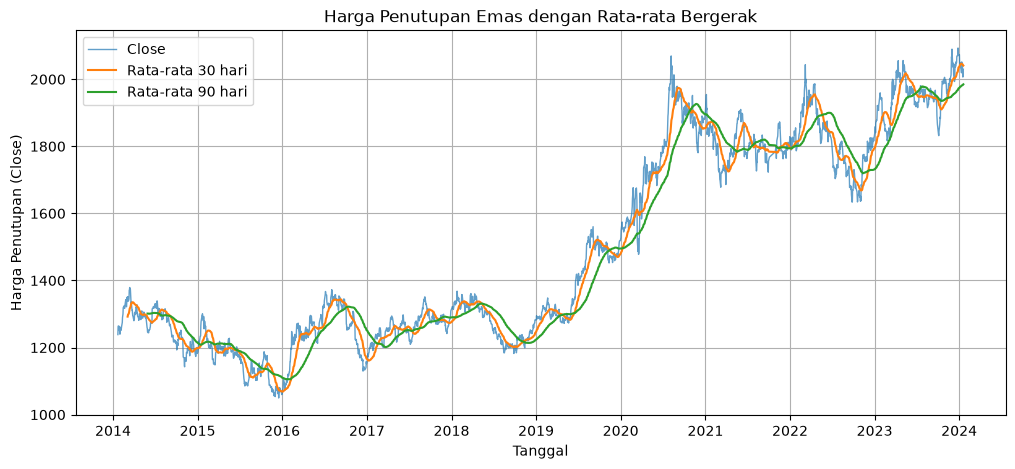

In [4]:
ma30 = df["Close"].rolling(30).mean()
ma90 = df["Close"].rolling(90).mean()

plt.figure()
plt.plot(df.index, df["Close"], label="Close", linewidth=1, alpha=0.7)
plt.plot(ma30.index, ma30, label="Rata-rata 30 hari", linewidth=1.5)
plt.plot(ma90.index, ma90, label="Rata-rata 90 hari", linewidth=1.5)
plt.title("Harga Penutupan Emas dengan Rata-rata Bergerak")
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan (Close)")
plt.legend()
plt.grid(True)
plt.savefig(SHOT_DIR / "ta_eda_01_tren_ma.png", dpi=150, bbox_inches="tight")
plt.show()

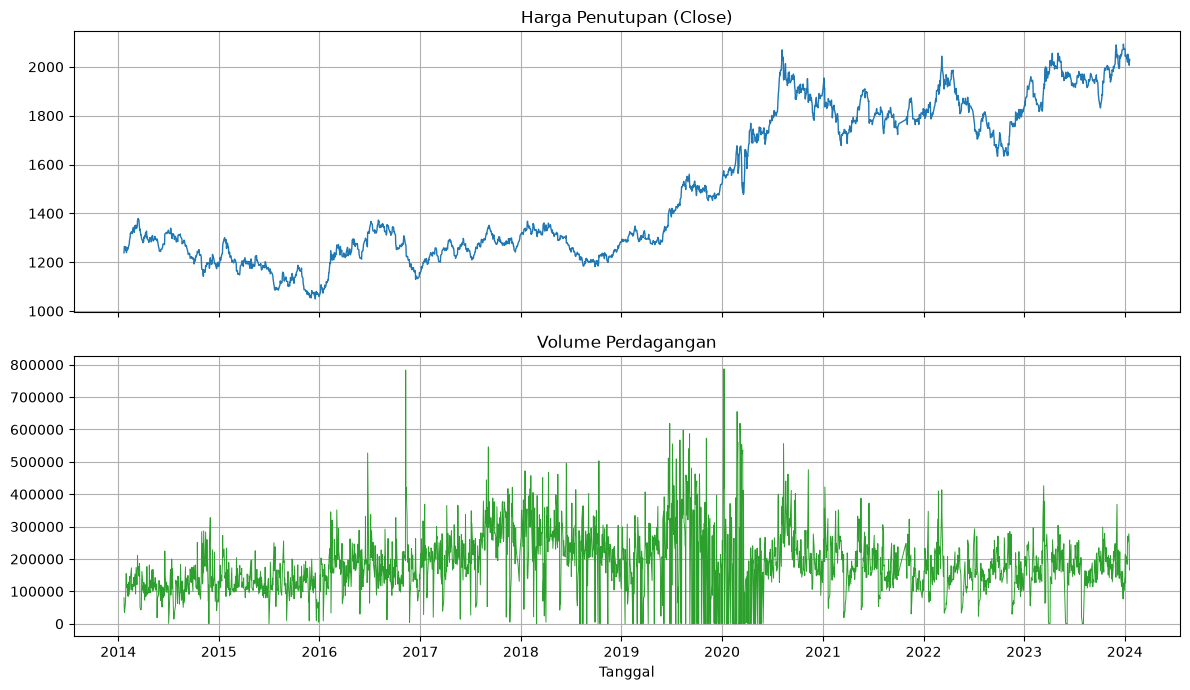

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(df.index, df["Close"], linewidth=1)
ax[0].set_title("Harga Penutupan (Close)")
ax[0].grid(True)
ax[1].plot(df.index, df["Volume"], linewidth=0.7, color="tab:green")
ax[1].set_title("Volume Perdagangan")
ax[1].set_xlabel("Tanggal")
ax[1].grid(True)
plt.tight_layout()
plt.savefig(SHOT_DIR / "ta_eda_02_harga_volume.png", dpi=150, bbox_inches="tight")
plt.show()

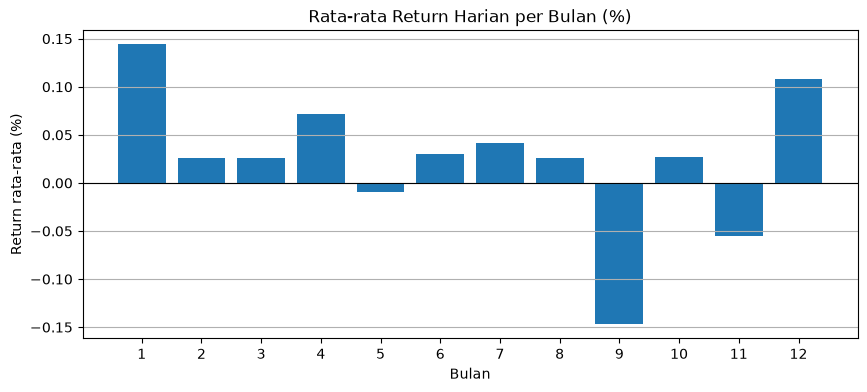

Rata-rata Close per tahun:
Date
2014    1267.8
2015    1158.8
2016    1251.7
2017    1260.6
2018    1272.0
2019    1397.1
2020    1779.7
2021    1801.0
2022    1808.7
2023    1954.1
2024    2036.1
Name: Close, dtype: float64


In [6]:
# Return harian dalam persen. Dipakai karena tren naik membuat harga mentah
# sulit dipakai untuk melihat pola musiman.
ret = df["Close"].pct_change().dropna() * 100
ret_per_bulan = ret.groupby(ret.index.month).mean()

plt.figure(figsize=(10, 4))
plt.bar(ret_per_bulan.index, ret_per_bulan.values)
plt.xticks(range(1, 13))
plt.title("Rata-rata Return Harian per Bulan (%)")
plt.xlabel("Bulan")
plt.ylabel("Return rata-rata (%)")
plt.axhline(0, color="black", linewidth=0.8)
plt.grid(True, axis="y")
plt.savefig(SHOT_DIR / "ta_eda_03_musiman.png", dpi=150, bbox_inches="tight")
plt.show()

print("Rata-rata Close per tahun:")
print(df["Close"].groupby(df.index.year).mean().round(1))

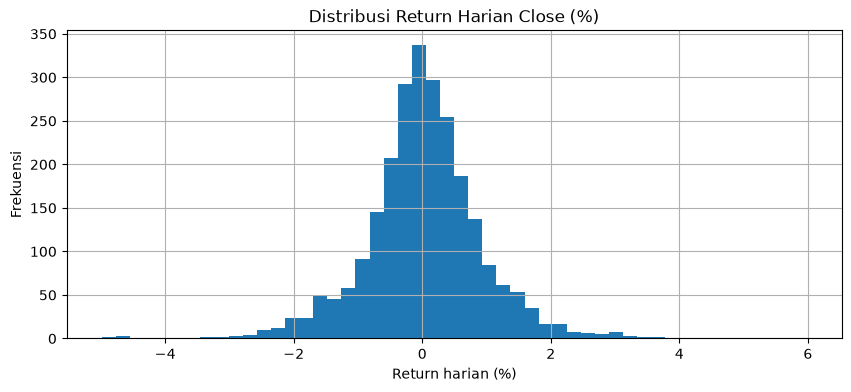

Statistik return harian (%):
count    2492.000
mean        0.024
std         0.932
min        -4.985
25%        -0.439
50%         0.021
75%         0.505
max         5.977
Name: Close, dtype: float64

Korelasi antar kolom:
        Close   Open   High    Low  Volume
Close   1.000  0.999  1.000  1.000   0.024
Open    0.999  1.000  0.999  0.999   0.028
High    1.000  0.999  1.000  0.999   0.032
Low     1.000  0.999  0.999  1.000   0.019
Volume  0.024  0.028  0.032  0.019   1.000


In [7]:
plt.figure(figsize=(10, 4))
plt.hist(ret, bins=50)
plt.title("Distribusi Return Harian Close (%)")
plt.xlabel("Return harian (%)")
plt.ylabel("Frekuensi")
plt.grid(True)
plt.savefig(SHOT_DIR / "ta_eda_04_distribusi_return.png", dpi=150, bbox_inches="tight")
plt.show()

print("Statistik return harian (%):")
print(ret.describe().round(3))
print("\nKorelasi antar kolom:")
print(df[["Close", "Open", "High", "Low", "Volume"]].corr().round(3))

In [8]:
close = df[["Close"]]                      # DataFrame 1 kolom (2D), format yang diminta scaler
train_end = int(len(close) * TRAIN_RATIO)  # batas data latih

print("Total data   :", len(close))
print("Data latih   :", train_end, "baris | s/d", close.index[train_end - 1].date())
print("Data uji     :", len(close) - train_end, "baris | mulai", close.index[train_end].date())

Total data   : 2493
Data latih   : 1994 baris | s/d 2022-01-19
Data uji     : 499 baris | mulai 2022-01-20


In [9]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(close.iloc[:train_end])         # belajar min/max HANYA dari data latih
scaled = scaler.transform(close)           # terapkan ke seluruh data

print("Min data latih  :", scaler.data_min_[0])
print("Max data latih  :", scaler.data_max_[0])
print("Rentang scaled latih:", scaled[:train_end].min().round(3), "-", scaled[:train_end].max().round(3))
print("Rentang scaled uji  :", scaled[train_end:].min().round(3), "-", scaled[train_end:].max().round(3))

Min data latih  : 1049.6
Max data latih  : 2069.4
Rentang scaled latih: 0.0 - 1.0
Rentang scaled uji  : 0.572 - 1.023


In [10]:
X, y, idx_target = [], [], []
for i in range(TIMESTEPS, len(scaled)):
    X.append(scaled[i - TIMESTEPS:i, 0])   # TIMESTEPS hari sebelumnya
    y.append(scaled[i, 0])                 # hari yang diprediksi
    idx_target.append(i)

X = np.array(X)
y = np.array(y)
idx_target = np.array(idx_target)

# Reshape ke (samples, timesteps, features)
X = X.reshape(X.shape[0], X.shape[1], 1)

# Pisahkan berdasarkan posisi hari target: latih jika target masuk data latih
mask_train = idx_target < train_end
X_train, y_train = X[mask_train], y[mask_train]
X_test, y_test = X[~mask_train], y[~mask_train]

print("X total  :", X.shape)
print("X_train  :", X_train.shape, "| y_train:", y_train.shape)
print("X_test   :", X_test.shape, "| y_test :", y_test.shape)

X total  : (2433, 60, 1)
X_train  : (1934, 60, 1) | y_train: (1934,)
X_test   : (499, 60, 1) | y_test : (499,)


In [11]:
# Window pertama harus sama dengan 60 data scaled pertama, targetnya data ke-61
ok_x = np.allclose(X_train[0, :, 0], scaled[0:TIMESTEPS, 0])
ok_y = np.isclose(y_train[0], scaled[TIMESTEPS, 0])
print("Window latih pertama benar :", ok_x)
print("Target latih pertama benar :", ok_y)

tgl_target_uji = close.index[idx_target[~mask_train][0]]
tgl_awal_window_uji = close.index[idx_target[~mask_train][0] - TIMESTEPS]
print("Sampel uji pertama memprediksi tanggal:", tgl_target_uji.date())
print("Window-nya memakai data mulai tanggal :", tgl_awal_window_uji.date())

Window latih pertama benar : True
Target latih pertama benar : True
Sampel uji pertama memprediksi tanggal: 2022-01-20
Window-nya memakai data mulai tanggal : 2021-09-29


In [12]:
joblib.dump(scaler, MODEL_DIR / "scaler.pkl")
cek = joblib.load(MODEL_DIR / "scaler.pkl")
print("Scaler tersimpan di:", MODEL_DIR / "scaler.pkl")
print("Cek muat ulang, max data latih:", cek.data_max_[0])

Scaler tersimpan di: ..\model\scaler.pkl
Cek muat ulang, max data latih: 2069.4


In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import json

tf.keras.utils.set_random_seed(42)   # agar hasil lebih konsisten antar-percobaan
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [13]:
# Validasi diambil dari 10% bagian PALING AKHIR data latih (tetap berurutan).
# Data uji tidak disentuh sama sekali sampai evaluasi.
val_size = int(len(X_train) * 0.1)
X_tr, y_tr = X_train[:-val_size], y_train[:-val_size]
X_val, y_val = X_train[-val_size:], y_train[-val_size:]

print("Data latih     :", X_tr.shape)
print("Data validasi  :", X_val.shape)
print("Data uji       :", X_test.shape)

Data latih     : (1741, 60, 1)
Data validasi  : (193, 60, 1)
Data uji       : (499, 60, 1)


In [14]:
model = Sequential([
    Input(shape=(TIMESTEPS, 1)),
    LSTM(units=50, return_sequences=True),
    Dropout(0.2),
    LSTM(units=50, return_sequences=False),
    Dropout(0.2),
    Dense(units=25),
    Dense(units=1)
])

model.compile(optimizer="adam", loss="mean_squared_error")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# EarlyStopping: berhenti otomatis jika val_loss tidak membaik selama 10 epoch,
# lalu bobot terbaik dikembalikan.
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_tr, y_tr,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=2
)

print("\nEpoch yang dijalankan :", len(history.history["loss"]))
print("Val loss terbaik      :", round(min(history.history["val_loss"]), 6))

Epoch 1/100
55/55 - 4s - 77ms/step - loss: 0.0161 - val_loss: 0.0013
Epoch 2/100
55/55 - 2s - 31ms/step - loss: 0.0025 - val_loss: 0.0012
Epoch 3/100
55/55 - 2s - 28ms/step - loss: 0.0018 - val_loss: 0.0022
Epoch 4/100
55/55 - 2s - 29ms/step - loss: 0.0018 - val_loss: 0.0023
Epoch 5/100
55/55 - 1s - 27ms/step - loss: 0.0019 - val_loss: 0.0018
Epoch 6/100
55/55 - 2s - 28ms/step - loss: 0.0016 - val_loss: 0.0028
Epoch 7/100
55/55 - 1s - 26ms/step - loss: 0.0014 - val_loss: 0.0010
Epoch 8/100
55/55 - 2s - 29ms/step - loss: 0.0013 - val_loss: 0.0013
Epoch 9/100
55/55 - 2s - 31ms/step - loss: 0.0014 - val_loss: 0.0011
Epoch 10/100
55/55 - 2s - 32ms/step - loss: 0.0013 - val_loss: 0.0013
Epoch 11/100
55/55 - 2s - 28ms/step - loss: 0.0013 - val_loss: 9.2900e-04
Epoch 12/100
55/55 - 2s - 32ms/step - loss: 0.0014 - val_loss: 0.0019
Epoch 13/100
55/55 - 2s - 35ms/step - loss: 0.0011 - val_loss: 0.0019
Epoch 14/100
55/55 - 4s - 76ms/step - loss: 0.0011 - val_loss: 0.0013
Epoch 15/100
55/55 - 4s -

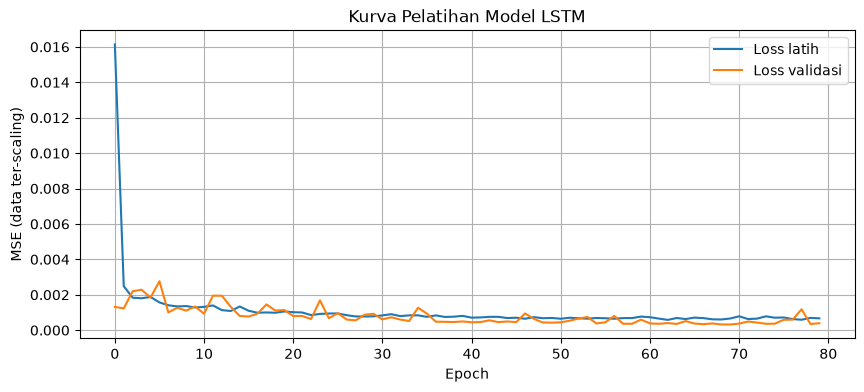

In [16]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Loss latih")
plt.plot(history.history["val_loss"], label="Loss validasi")
plt.title("Kurva Pelatihan Model LSTM")
plt.xlabel("Epoch")
plt.ylabel("MSE (data ter-scaling)")
plt.legend()
plt.grid(True)
plt.savefig(SHOT_DIR / "ta_kurva_pelatihan.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Prediksi pada data uji, lalu kembalikan ke skala harga asli
pred_scaled = model.predict(X_test, verbose=0)
pred = scaler.inverse_transform(pred_scaled)
actual = scaler.inverse_transform(y_test.reshape(-1, 1))

rmse = float(np.sqrt(mean_squared_error(actual, pred)))
mae = float(mean_absolute_error(actual, pred))
mape = float(mean_absolute_percentage_error(actual, pred) * 100)

print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"RMSE sebagai % dari rata-rata harga uji: {rmse / actual.mean() * 100:.2f}%")

# Simpan hasil prediksi bersama tanggalnya
tgl_uji = close.index[idx_target[~mask_train]]
hasil = pd.DataFrame({"Date": tgl_uji, "Aktual": actual.ravel(), "Prediksi": pred.ravel()})
hasil.head()

RMSE : 20.87
MAE  : 16.11
MAPE : 0.85%
RMSE sebagai % dari rata-rata harga uji: 1.11%


,Date,Aktual,Prediksi
0,2022-01-20,1844.9,1826.973755
1,2022-01-21,1834.1,1836.032104
2,2022-01-24,1844.2,1835.248047
3,2022-01-25,1855.0,1837.565674
4,2022-01-26,1832.0,1844.133179


In [18]:
# Baseline "naif": menebak harga besok = harga hari terakhir di window.
# Ini bukan ketentuan modul, tetapi berguna agar kita tahu apakah LSTM
# benar-benar lebih baik daripada tebakan paling sederhana.
naive = scaler.inverse_transform(X_test[:, -1, :])
rmse_naive = float(np.sqrt(mean_squared_error(actual, naive)))
mae_naive = float(mean_absolute_error(actual, naive))

perbandingan = pd.DataFrame({
    "Model": ["LSTM", "Baseline naif (harga kemarin)"],
    "RMSE": [round(rmse, 2), round(rmse_naive, 2)],
    "MAE": [round(mae, 2), round(mae_naive, 2)],
})
perbandingan

,Model,RMSE,MAE
0,LSTM,20.87,16.11
1,Baseline naif (harga kemarin),17.35,12.97


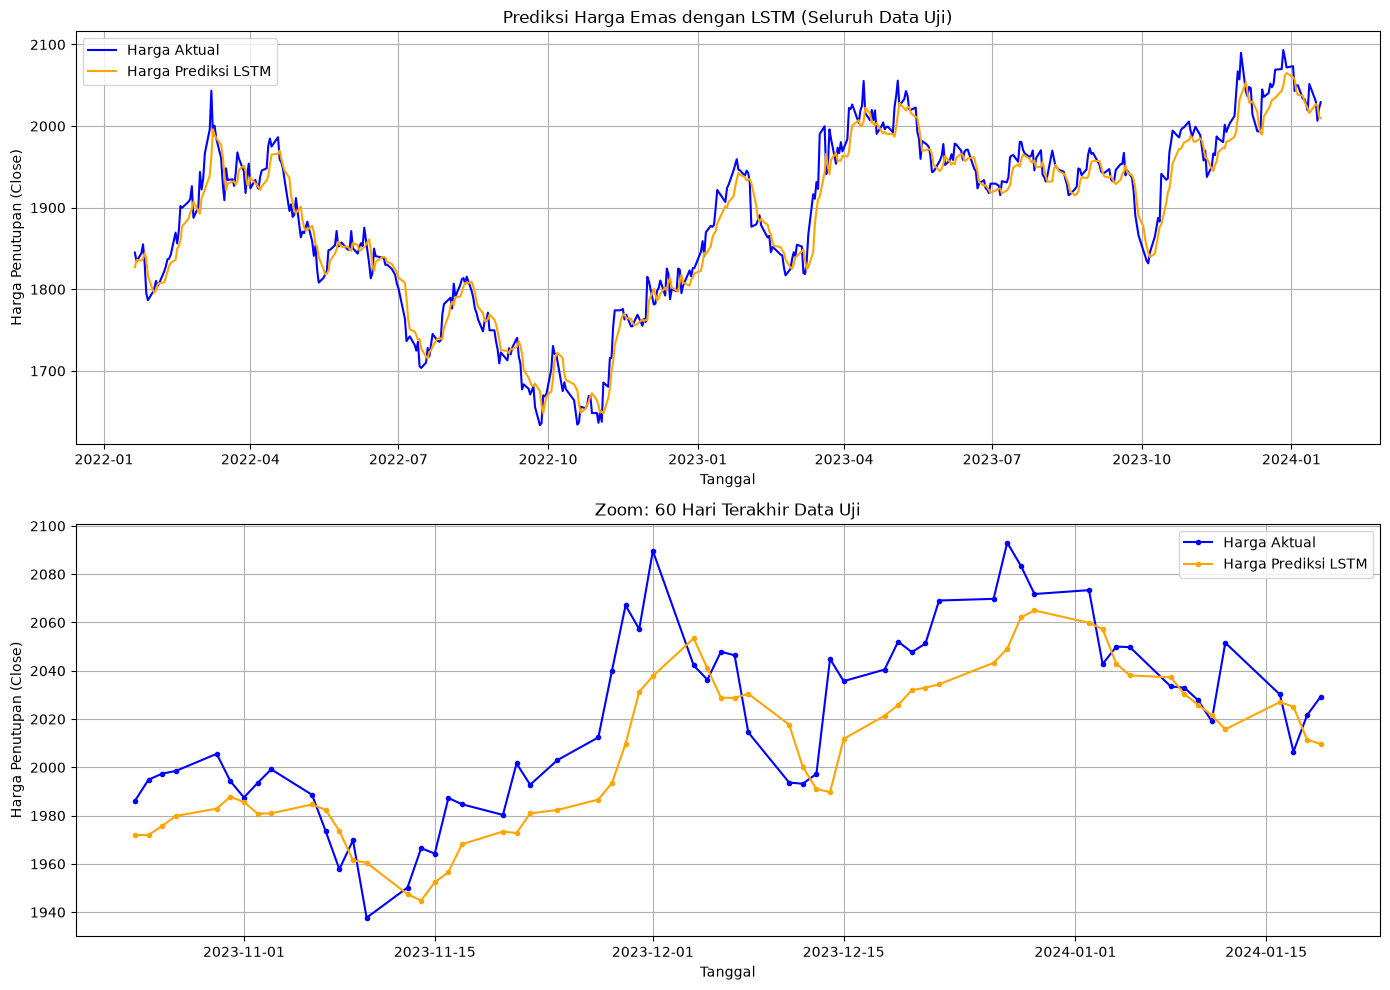

In [19]:
fig, ax = plt.subplots(2, 1, figsize=(14, 10))

# Seluruh data uji
ax[0].plot(hasil["Date"], hasil["Aktual"], color="blue", label="Harga Aktual")
ax[0].plot(hasil["Date"], hasil["Prediksi"], color="orange", label="Harga Prediksi LSTM")
ax[0].set_title("Prediksi Harga Emas dengan LSTM (Seluruh Data Uji)")
ax[0].set_xlabel("Tanggal")
ax[0].set_ylabel("Harga Penutupan (Close)")
ax[0].legend()
ax[0].grid(True)

# Zoom 60 hari terakhir agar selisih per hari terlihat jelas
zoom = hasil.tail(60)
ax[1].plot(zoom["Date"], zoom["Aktual"], color="blue", marker="o", markersize=3, label="Harga Aktual")
ax[1].plot(zoom["Date"], zoom["Prediksi"], color="orange", marker="o", markersize=3, label="Harga Prediksi LSTM")
ax[1].set_title("Zoom: 60 Hari Terakhir Data Uji")
ax[1].set_xlabel("Tanggal")
ax[1].set_ylabel("Harga Penutupan (Close)")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.savefig(SHOT_DIR / "ta_aktual_vs_prediksi.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
hasil.to_csv(MODEL_DIR / "pred_test.csv", index=False)

metrik = {
    "timesteps": TIMESTEPS,
    "jumlah_data_latih": int(len(X_train)),
    "jumlah_data_uji": int(len(X_test)),
    "rmse": round(rmse, 4),
    "mae": round(mae, 4),
    "mape_persen": round(mape, 4),
    "rmse_baseline_naif": round(rmse_naive, 4),
    "mae_baseline_naif": round(mae_naive, 4),
    "tanggal_uji_awal": str(tgl_uji[0].date()),
    "tanggal_uji_akhir": str(tgl_uji[-1].date()),
}
with open(MODEL_DIR / "metrics.json", "w") as f:
    json.dump(metrik, f, indent=2)

print(json.dumps(metrik, indent=2))

{
  "timesteps": 60,
  "jumlah_data_latih": 1934,
  "jumlah_data_uji": 499,
  "rmse": 20.8728,
  "mae": 16.1137,
  "mape_persen": 0.8527,
  "rmse_baseline_naif": 17.3524,
  "mae_baseline_naif": 12.9671,
  "tanggal_uji_awal": "2022-01-20",
  "tanggal_uji_akhir": "2024-01-19"
}


In [21]:
model.save(MODEL_DIR / "lstm_gold.h5")      # format .h5 sesuai modul
model.save(MODEL_DIR / "lstm_gold.keras")   # format native Keras 3 (cadangan)

# Uji: model yang dimuat ulang harus menghasilkan prediksi yang sama
model_cek = tf.keras.models.load_model(MODEL_DIR / "lstm_gold.h5", compile=False)
p1 = model.predict(X_test[:5], verbose=0)
p2 = model_cek.predict(X_test[:5], verbose=0)
print("Model hasil muat ulang identik:", np.allclose(p1, p2, atol=1e-5))
print("Isi folder model:", sorted(p.name for p in MODEL_DIR.iterdir()))

Model hasil muat ulang identik: True
Isi folder model: ['lstm_gold.h5', 'lstm_gold.keras', 'metrics.json', 'pred_test.csv', 'scaler.pkl']


In [14]:
# Muat model yang sudah dilatih dan disimpan di Sel 21 (tanpa melatih ulang)
model = tf.keras.models.load_model(MODEL_DIR / "lstm_gold.h5", compile=False)

# Bukti bahwa ini model yang sama: prediksinya harus sama dengan yang tersimpan di pred_test.csv
tersimpan = pd.read_csv(MODEL_DIR / "pred_test.csv")
pred_cek = scaler.inverse_transform(model.predict(X_test, verbose=0)).ravel()
print("Model berhasil dimuat.")
print("Selisih maksimum vs prediksi tersimpan:", float(np.abs(pred_cek - tersimpan["Prediksi"].to_numpy()).max()))

Model berhasil dimuat.
Selisih maksimum vs prediksi tersimpan: 0.00010351562514188117


In [15]:
def ramal_ke_depan(model, scaler, harga_close, langkah=7, timesteps=60):
    """Ramal 'langkah' hari ke depan secara berantai: hasil prediksi dipakai
    sebagai input untuk hari berikutnya."""
    window = scaler.transform(np.array(harga_close[-timesteps:]).reshape(-1, 1))
    window = window.reshape(1, timesteps, 1)
    hasil_scaled = []
    for _ in range(langkah):
        p = model.predict(window, verbose=0)[0, 0]
        hasil_scaled.append(p)
        window = np.concatenate([window[:, 1:, :], np.array(p).reshape(1, 1, 1)], axis=1)
    return scaler.inverse_transform(np.array(hasil_scaled).reshape(-1, 1)).ravel()

ramalan = ramal_ke_depan(model, scaler, close["Close"].values, langkah=7, timesteps=TIMESTEPS)
for i, nilai in enumerate(ramalan, start=1):
    print(f"Hari ke-{i} setelah {close.index[-1].date()} : {nilai:.2f}")

c:\Users\HP\Downloads\TUGAS\TA04-LSTM-Gold\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Hari ke-1 setelah 2024-01-19 : 2013.99
Hari ke-2 setelah 2024-01-19 : 2010.11
Hari ke-3 setelah 2024-01-19 : 2005.15
Hari ke-4 setelah 2024-01-19 : 2000.22
Hari ke-5 setelah 2024-01-19 : 1995.57
Hari ke-6 setelah 2024-01-19 : 1991.22
Hari ke-7 setelah 2024-01-19 : 1987.14


In [16]:
bobot = model.get_weights()
np.savez(MODEL_DIR / "lstm_weights.npz", *bobot)
print("Jumlah array bobot:", len(bobot))
print("Bentuk tiap array :", [w.shape for w in bobot])
print("Isi folder model  :", sorted(p.name for p in MODEL_DIR.iterdir()))

Jumlah array bobot: 10
Bentuk tiap array : [(1, 200), (50, 200), (200,), (50, 200), (50, 200), (200,), (50, 25), (25,), (25, 1), (1,)]
Isi folder model  : ['lstm_gold.h5', 'lstm_gold.keras', 'lstm_weights.npz', 'metrics.json', 'pred_test.csv', 'scaler.pkl']


In [17]:
import sys
sys.path.append(str(ROOT.resolve()))   # agar predictor.py di folder utama bisa diimpor
from predictor import LSTMPredictor

pred_np = LSTMPredictor(MODEL_DIR / "lstm_weights.npz")

p_keras = model.predict(X_test, verbose=0)
p_numpy = pred_np.predict(X_test)
print("Selisih maksimum prediksi Keras vs NumPy:", float(np.abs(p_keras - p_numpy).max()))

ram_numpy = pred_np.ramal(scaler, close["Close"].values, 7, TIMESTEPS)
print("\nRamalan 7 hari  (Keras)  :", np.round(ramalan, 2))
print("Ramalan 7 hari  (NumPy)  :", np.round(ram_numpy, 2))

Selisih maksimum prediksi Keras vs NumPy: 2.384185791015625e-07

Ramalan 7 hari  (Keras)  : [2013.99 2010.11 2005.15 2000.22 1995.57 1991.22 1987.14]
Ramalan 7 hari  (NumPy)  : [2013.99 2010.11 2005.15 2000.22 1995.57 1991.22 1987.14]
